# Notes

<b>Parameters:</b>
1. Pull
    - pull onset (3 SD above 1s baseline at the beginning?, last local minimum before main peak?)
    - pull magnitude (peak velocity or acceleration magnitude)

2. Steps (corrective)
    - number of steps
    - latency of first step (relative to pull onset)
    - length of first step (compared to baseline foot position)
    - velocity of first step (average, not peak)
    - TODO: <mark> min step length/time? hopping or repositionin counts? </mark>

3. Trunk
    - bilateral shoulder & hip keypoints
    - max retropulsion angle (compared to baseline)
    - recovery time (when it goes back to >75% of max angle and stepping is done)

<b>Other</b>
- at leat 0.5s baseline before each pull
- no well established consesus on velocity or acceleration
- participant should be as close to the camera as possible

# Setup

In [33]:
import os
import json 
import numpy as np
from util import get_velocity_and_acceleration, load_keypoints_and_labels
from pulltest_util import get_axis_velocity, get_pull_onsets,segment_pulls, GaitEvent, get_gait_events, Pull
from scipy.signal import find_peaks, peak_widths
import matplotlib.pyplot as plt
%matplotlib ipympl
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [34]:
# load preprocessed keypoints
recording_name = "pq1"
filename_stereo = os.path.join("data", recording_name, recording_name + "_stereo.npz")
filename_stereo_metadata = os.path.join("data", recording_name, recording_name + "_metadata.json")

filename_qualisys = os.path.join("data", recording_name, recording_name + "_qualisys.npz")

for filename in [filename_stereo, filename_stereo_metadata, filename_qualisys]:
    if not os.path.exists(filename):
        raise FileNotFoundError(f"File {filename} does not exist")


stereo_keypoints, stereo_labels = load_keypoints_and_labels(filename=filename_stereo)
print(f"shape: {stereo_keypoints.shape}")

qualisys_keypoints, qualisys_labels = load_keypoints_and_labels(filename=filename_qualisys)
print(f"shape: {qualisys_keypoints.shape}")

with open(filename_stereo_metadata) as f:
    stereo_metadata = json.load(f)

loaded data from: data\pq1\pq1_stereo.npz with keys: ['labels', 'keypoints']
shape: (6422, 19, 3)
loaded data from: data\pq1\pq1_qualisys.npz with keys: ['labels', 'keypoints']
shape: (6887, 10, 3)


# Segment pulls

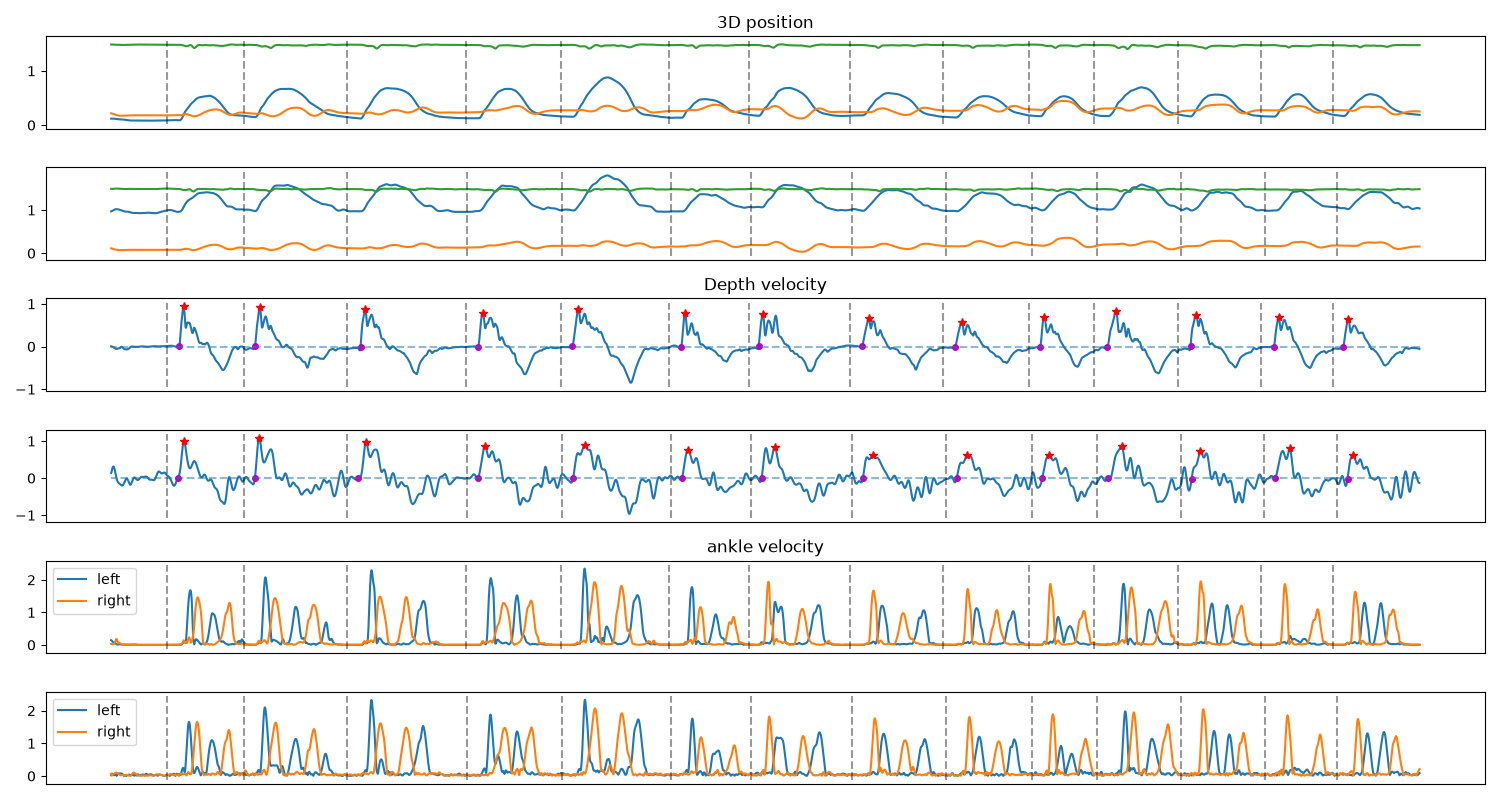

In [3]:
# 3D velocity & acceleration

stereo_cut = 390
qualisys_cut = 6050

qualisys_shoulder = qualisys_keypoints[:qualisys_cut, qualisys_labels.index("mid_shoulder"), :]
stereo_shoulder = stereo_keypoints[stereo_cut:, stereo_labels.index("mid_shoulder"), :]

qualisys_shoulder_velocity = get_axis_velocity(qualisys_shoulder, 0, 100)
stereo_shoulder_velocity = get_axis_velocity(stereo_shoulder, 0, 100)

stereo_left_ankle = stereo_keypoints[stereo_cut:, stereo_labels.index("left_ankle"), :]
qualisys_left_ankle = qualisys_keypoints[:qualisys_cut, qualisys_labels.index("left_ankle"), :]
stereo_right_ankle = stereo_keypoints[stereo_cut:, stereo_labels.index("right_ankle"), :]
qualisys_right_ankle = qualisys_keypoints[:qualisys_cut, qualisys_labels.index("right_ankle"), :]

qualisys_left_ankle_velocity = np.linalg.norm(get_axis_velocity(qualisys_left_ankle, None, 100), axis=1)
stereo_left_ankle_velocity = np.linalg.norm(get_axis_velocity(stereo_left_ankle, None, 100), axis=1)
qualisys_right_ankle_velocity = np.linalg.norm(get_axis_velocity(qualisys_right_ankle, None, 100), axis=1)
stereo_right_ankle_velocity = np.linalg.norm(get_axis_velocity(stereo_right_ankle, None, 100), axis=1)

stereo_peak_indices, stereo_onsets, stereo_ends = get_pull_onsets(velocity=stereo_shoulder_velocity)
qualisys_peak_indices, qualisys_onsets, qualisys_ends = get_pull_onsets(velocity=qualisys_shoulder_velocity)


if True:
    plt.close("all")
    fig, axs = plt.subplots(6, 1, figsize=(15, 8))

    axs[0].set_title("3D position")
    axs[0].plot(qualisys_shoulder, label=["depth", "vertical", "horizontal"])
    axs[1].plot(stereo_shoulder)

    axs[2].set_title("Depth velocity")
    axs[2].plot(qualisys_shoulder_velocity)
    axs[2].plot(qualisys_peak_indices, qualisys_shoulder_velocity[qualisys_peak_indices], "r*")
    axs[2].plot(qualisys_onsets, qualisys_shoulder_velocity[qualisys_onsets], "mo", markersize=4)
    # axs[2].plot(qualisys_ends, qualisys_shoulder_velocity[qualisys_ends], "co", markersize=4)    
    axs[2].hlines(0, len(qualisys_shoulder_velocity), 0, linestyle="--", alpha=0.5)

    axs[3].plot(stereo_shoulder_velocity)
    axs[3].plot(stereo_peak_indices, stereo_shoulder_velocity[stereo_peak_indices], "r*")
    axs[3].plot(stereo_onsets, stereo_shoulder_velocity[stereo_onsets], "mo", markersize=4)
    # axs[3].plot(stereo_ends, stereo_shoulder_velocity[stereo_ends], "co", markersize=4)
    axs[3].hlines(0, len(stereo_shoulder_velocity), 0, linestyle="--", alpha=0.5)

    axs[4].set_title("ankle velocity")
    axs[4].plot(qualisys_left_ankle_velocity, label="left")
    axs[4].plot(qualisys_right_ankle_velocity, label="right")
    axs[4].legend(loc="upper left")
    axs[5].plot(stereo_left_ankle_velocity, label="left")
    axs[5].plot(stereo_right_ankle_velocity, label="right")
    axs[5].legend(loc="upper left")
    for ax in axs:
        ax.set_xticks([])
        ax_ymin, ax_ymax = ax.get_ylim()
        for start, end in zip(stereo_onsets, stereo_ends):
            # ax.vlines(start, ax_ymin, ax_ymax, color="k", linestyles="--", alpha=0.4)
            ax.vlines(start-50, ax_ymin, ax_ymax, color="k", linestyles="--", alpha=0.4)

    plt.tight_layout()

In [4]:
stereo_pulls = segment_pulls(stereo_onsets, len(stereo_shoulder))
# qualisys_pulls = segment_pulls(qualisys_onsets, len(qualisys_shoulder))
stereo_pulls

# Detect steps

In [19]:
ankles = {"left": stereo_left_ankle, "right": stereo_right_ankle}
gait_events = get_gait_events(ankle_positions=ankles, fps=100, speed_threshold=0.3, min_swing_time=0.3, min_stance_time=0.3,show_debug_figure=False)
gait_events

[GaitEvent(kind='FC', frame=344, side='left', perspective=None, segment=None, segment_index=None, relative_position=None),
 GaitEvent(kind='FC', frame=376, side='right', perspective=None, segment=None, segment_index=None, relative_position=None),
 GaitEvent(kind='IC', frame=377, side='left', perspective=None, segment=None, segment_index=None, relative_position=None),
 GaitEvent(kind='IC', frame=418, side='right', perspective=None, segment=None, segment_index=None, relative_position=None),
 GaitEvent(kind='FC', frame=444, side='left', perspective=None, segment=None, segment_index=None, relative_position=None),
 GaitEvent(kind='IC', frame=496, side='left', perspective=None, segment=None, segment_index=None, relative_position=None),
 GaitEvent(kind='FC', frame=511, side='right', perspective=None, segment=None, segment_index=None, relative_position=None),
 GaitEvent(kind='IC', frame=564, side='right', perspective=None, segment=None, segment_index=None, relative_position=None),
 GaitEvent(k

# Trunk angle

In [ ]:
mid_hip = stereo_keypoints[:, stereo_labels.index('mid_hip'),:]
mid_shoulder = stereo_keypoints[:,stereo_labels.index('mid_shoulder'),:]
torso = mid_shoulder-mid_hip


(6422, 3)

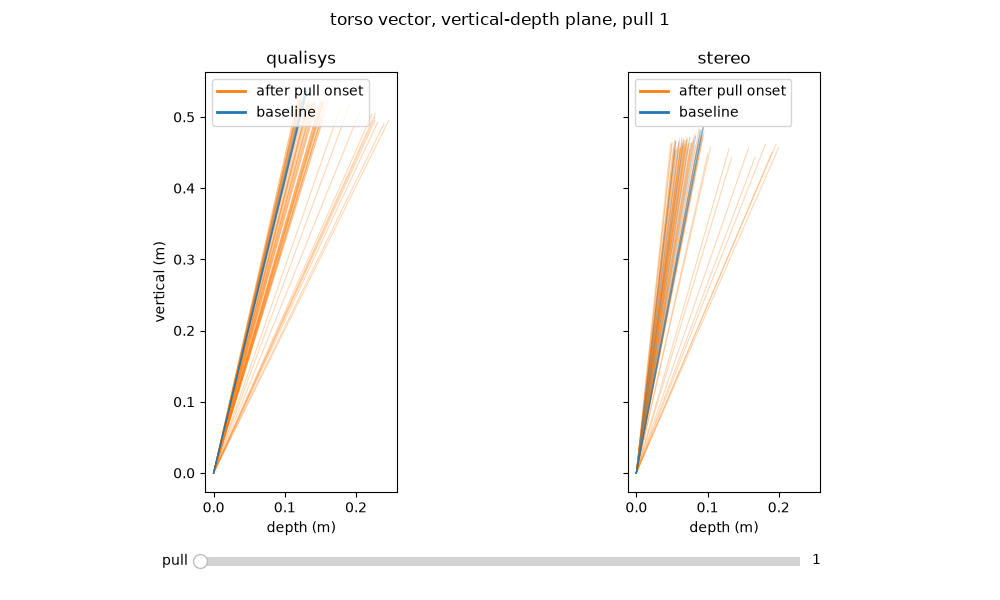

In [28]:
# torso vector (mid_hip -> mid_shoulder) of one pull projected onto the vertical-depth (sagittal) plane, drawn in 2D,
# qualisys and stereo side by side, with a slider to select the pull
# needs qualisys_recording and stereo_recording from the "full" section; their keypoints are already cut,
# so pull frames index them directly
from matplotlib.widgets import Slider
from util import project_vector_on_plane

DRAW_FREQUENCY = 20  # Hz, torso vectors drawn per second; None draws every frame
horizontal_axis_normal = np.array([0, 1, 0])  # the vertical-depth plane is orthogonal to the horizontal axis
recordings = [qualisys_recording, stereo_recording]

# project once, the slider only redraws
torso_projected_by_system = {}
for recording in recordings:
    recording_mid_hip = recording.keypoints[:, recording.labels.index("mid_hip"), :]
    recording_mid_shoulder = recording.keypoints[:, recording.labels.index("mid_shoulder"), :]
    recording_torso = recording_mid_shoulder - recording_mid_hip
    torso_projected_by_system[recording.system] = np.array(
        [project_vector_on_plane(horizontal_axis_normal, torso_vector) for torso_vector in recording_torso]
    )  # (frames, 3), horizontal component is 0


def draw_torso_pull(pull_number, draw_frequency=None):
    """
    Draw the torso vectors of one pull for every recording.

    Args:
        pull_number: 1-based pull number
        draw_frequency: torso vectors drawn per second (Hz); None draws every frame
    """
    fig.suptitle(f"torso vector, vertical-depth plane, pull {pull_number}")
    for ax, recording in zip(axs, recordings):
        ax.clear()
        torso_projected = torso_projected_by_system[recording.system]
        pull = recording.pulls[pull_number - 1]
        frame_step = 1 if draw_frequency is None else max(1, round(recording.fps / draw_frequency))
        # baseline is drawn last so it stays visible on top of the post-onset vectors
        phases = {
            "after pull onset": (range(pull.pull_onset, pull.end, frame_step), "tab:orange"),
            "baseline": (range(pull.start, pull.pull_onset, frame_step), "tab:blue"),
        }

        ax.set_title(recording.system)
        for phase_name, (phase_frames, phase_color) in phases.items():
            for frame_index in phase_frames:
                depth_component, _, vertical_component = torso_projected[frame_index]
                ax.plot(
                    [0, depth_component],
                    [0, vertical_component],
                    color=phase_color,
                    alpha=0.3,
                    linewidth=0.8,
                    label=phase_name if frame_index == phase_frames[0] else None,
                )
        ax.set_xlabel("depth (m)")
        ax.set_aspect("equal")
        legend = ax.legend(loc="upper left")
        for legend_line in legend.get_lines():
            legend_line.set_alpha(1)
            legend_line.set_linewidth(2)
    axs[0].set_ylabel("vertical (m)")
    fig.canvas.draw_idle()


plt.close("all")
fig, axs = plt.subplots(1, 2, figsize=(10, 6), sharex=True, sharey=True)
fig.subplots_adjust(bottom=0.18)
pull_count = min(len(recording.pulls) for recording in recordings)
slider_ax = fig.add_axes([0.2, 0.05, 0.6, 0.03])
# keep a reference to the slider, otherwise it is garbage collected and stops responding
pull_slider = Slider(slider_ax, "pull", valmin=1, valmax=pull_count, valinit=1, valstep=1)
pull_slider.on_changed(lambda pull_number: draw_torso_pull(int(pull_number), DRAW_FREQUENCY))
draw_torso_pull(1, DRAW_FREQUENCY)

# full

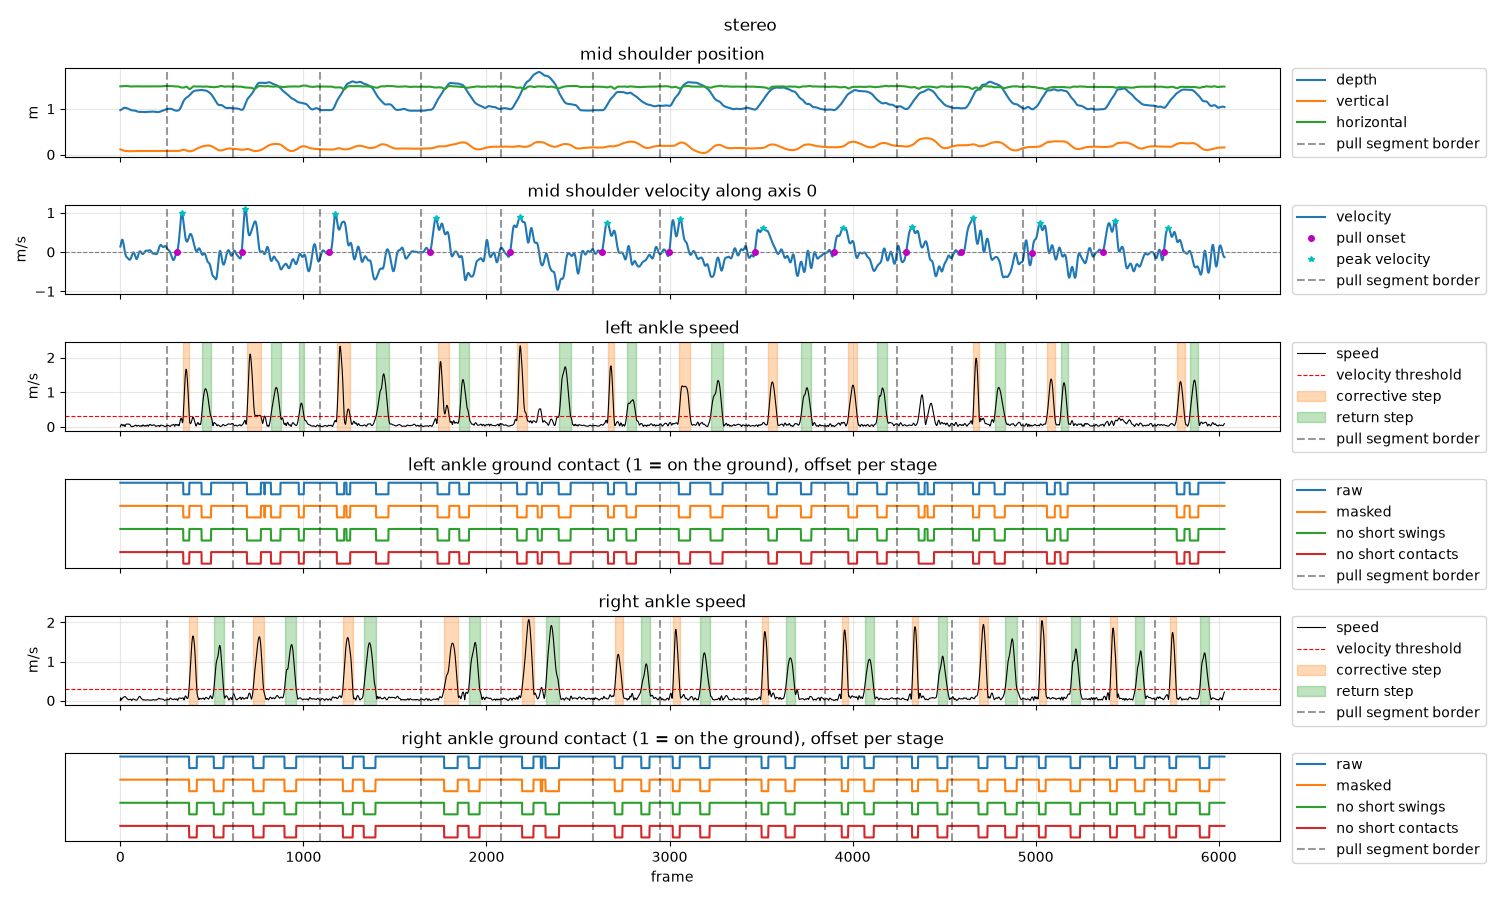

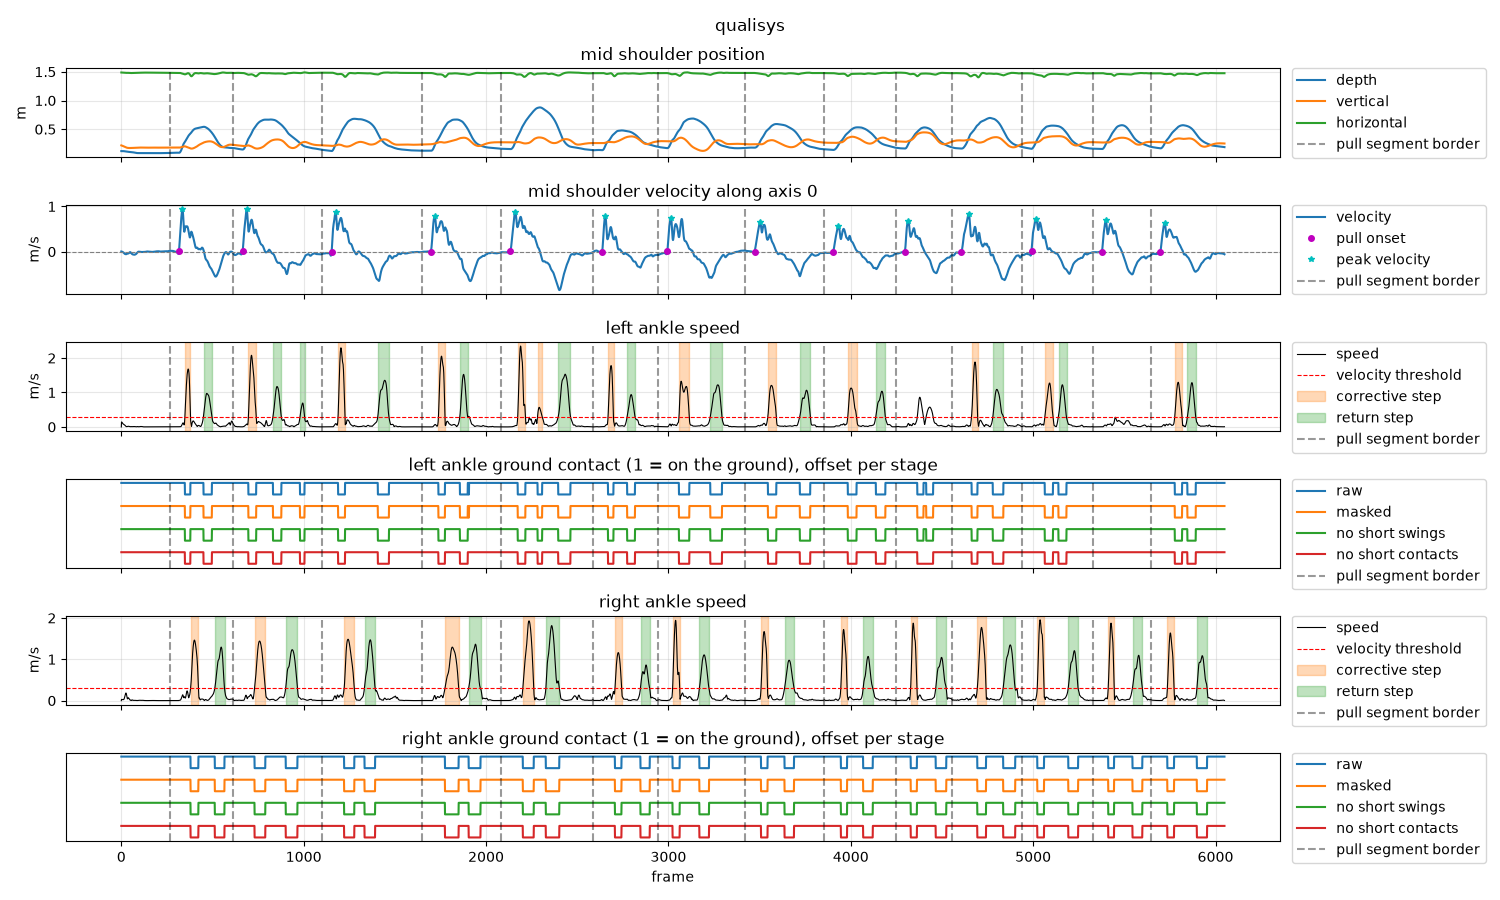

In [37]:
# full pipeline per system: pull onsets -> segments -> gait events -> steps -> pulls with classified steps
from pulltest_util import Recording

ANALYSIS_PARAMETERS = dict(
    pull_axis=0,  # depth
    baseline_time=0.5,  # s before each pull onset
    speed_threshold=0.3,  # m/s, ankle speed below which the foot is on the ground
    min_swing_time=0.2,  # s
    min_stance_time=0.2,  # s
    min_step_length=0.1,  # m, shorter steps are shuffles
)

stereo_cut = 390
qualisys_cut = 6050

qualisys_recording = Recording("qualisys", qualisys_keypoints[:qualisys_cut], qualisys_labels, fps=100)
stereo_recording = Recording("stereo", stereo_keypoints[stereo_cut:], stereo_labels, fps=100)
for recording in [qualisys_recording, stereo_recording]:
    recording.analyze(**ANALYSIS_PARAMETERS)

stereo_fig = stereo_recording.plot()
qualisys_fig = qualisys_recording.plot()

In [32]:
print(stereo_recording.pulls[0])

Pull: frames 257-613, onset 307
  baseline ankle position: [1.103 0.064 0.123]
  baseline trunk: [0.079 0.014 0.475]
  max trunk angle: 14.23 deg, frame 347
  recovery time: 0.55 s
  steps: 4
  corrective step count: 2
  first corrective step latency: 0.37 s
  first corrective step length: 0.36 m
  first corrective step velocity: 1.09 m/s
    type        side       FC    IC  length  velocity
    corrective  left      344   377    0.36      1.09
    corrective  right     376   418    0.44      1.06
    return      left      444   496    0.39      0.75
    return      right     511   564    0.46      0.86


In [26]:
s,e = stereo_recording.pulls[9].start, stereo_recording.pulls[9].end
[ge for ge in stereo_recording.gait_events if ge.side=='left' and ge.frame>s and ge.frame<e]

[GaitEvent(type='FC', frame=4361, side='left', perspective=None, segment=None, segment_index=None, relative_position=None),
 GaitEvent(type='IC', frame=4445, side='left', perspective=None, segment=None, segment_index=None, relative_position=None)]

In [27]:
stereo_recording.steps

[Step(FC=GaitEvent(type='FC', frame=344, side='left', perspective=None, segment=None, segment_index=None, relative_position=None), IC=GaitEvent(type='IC', frame=377, side='left', perspective=None, segment=None, segment_index=None, relative_position=None), step_length=0.3600987345939054, step_velocity=1.091208286648198, type='corrective'),
 Step(FC=GaitEvent(type='FC', frame=376, side='right', perspective=None, segment=None, segment_index=None, relative_position=None), IC=GaitEvent(type='IC', frame=418, side='right', perspective=None, segment=None, segment_index=None, relative_position=None), step_length=0.44385302429730233, step_velocity=1.056792914993577, type='corrective'),
 Step(FC=GaitEvent(type='FC', frame=444, side='left', perspective=None, segment=None, segment_index=None, relative_position=None), IC=GaitEvent(type='IC', frame=496, side='left', perspective=None, segment=None, segment_index=None, relative_position=None), step_length=0.3906116452335732, step_velocity=0.75117624083

In [12]:
for idx, pull in enumerate(stereo_recording.pulls, start=1):
    print(idx, pull, '\n')

1 Pull: frames 257-613, onset 307
  baseline ankle position: [1.103 0.064 0.123]
  baseline trunk: [0.079 0.014 0.475]
  max trunk angle: 14.23 deg, frame 347
  recovery time: 0.55 s
  steps: 4
  corrective step count: 2
  first corrective step latency: 0.37 s
  first corrective step length: 0.36 m
  first corrective step velocity: 1.09 m/s
    type        side       FC    IC  length  velocity
    corrective  left      344   377    0.36      1.09
    corrective  right     376   418    0.44      1.06
    return      left      444   496    0.39      0.75
    return      right     511   564    0.46      0.86 

2 Pull: frames 613-1089, onset 663
  baseline ankle position: [1.109 0.093 0.121]
  baseline trunk: [0.065 0.015 0.461]
  max trunk angle: 16.57 deg, frame 695
  recovery time: 0.54 s
  steps: 5
  corrective step count: 2
  first corrective step latency: 0.29 s
  first corrective step length: 0.63 m
  first corrective step velocity: 0.84 m/s
    type        side       FC    IC  leng

In [4]:
for idx, (q_pull, s_pull) in enumerate(
    zip(qualisys_recording.pulls, stereo_recording.pulls), start=1
):
    print(
        f"Pull {idx}\nsteps: {q_pull.corrective_step_count}, {s_pull.corrective_step_count} \nlatency: {q_pull.first_corrective_step_latency}, {s_pull.first_corrective_step_latency}\n"
    )

Pull 1
steps: 2, 2 
latency: 0.33, 0.37

Pull 2
steps: 2, 2 
latency: 0.32, 0.29

Pull 3
steps: 2, 2 
latency: 0.36, 0.44

Pull 4
steps: 2, 2 
latency: 0.43, 0.42

Pull 5
steps: 3, 2 
latency: 0.41, 0.38

Pull 6
steps: 2, 2 
latency: 0.33, 0.33

Pull 7
steps: 2, 2 
latency: 0.29, 0.19

Pull 8
steps: 2, 2 
latency: 0.36, 0.37

Pull 9
steps: 2, 2 
latency: 0.44, 0.43

Pull 10
steps: 1, 1 
latency: 0.33, 0.32

Pull 11
steps: 2, 2 
latency: 0.57, 0.64

Pull 12
steps: 2, 2 
latency: 0.32, 0.37

Pull 13
steps: 1, 1 
latency: 0.35, 0.4

Pull 14
steps: 2, 2 
latency: 0.38, 0.31

